# ICU occupancy forecast

**Question:** how many ICU beds will be occupied in 6, 12, 24, 48 and 72 hours?

**Data:** hourly occupancy rebuilt from the simulated hospital's 180-day history
(`python manage.py export_occupancy` in the backend).

**Approach:** for each horizon, a Gradient Boosting model is compared with simple rules and with a classical
statistical method. The data is split in time:

| Period | Used for |
|---|---|
| Older months | training |
| The **2 weeks** before the test | **validation**: choosing the best method for each horizon |
| The **last 30 days** | the **test**: never seen while training or choosing; all reported results come from here |

The comparisons:

| Comparison | Idea |
|---|---|
| **Same as now** (persistence) | occupancy won't change |
| **Same time last week** (seasonal naive) | the weekly rhythm repeats |
| **Holt-Winters** (seasonal exponential smoothing) | learns the daily and weekly pattern, but doesn't use the current situation |

The **uncertainty band** is calibrated on the validation weeks: it's made just wide enough that 80% of the
validation errors fall inside it (a simple form of *conformal prediction*).

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing

DATA, MODELS, RESULTS = Path("../data"), Path("../models"), Path("../results")
RESULTS.mkdir(exist_ok=True)

data = pd.read_csv(DATA / "occupancy_hourly.csv", parse_dates=["time"]).set_index("time")
data.index = data.index.tz_convert("Asia/Kolkata")  # local time, so "8 am" and "Monday" mean what they say
info = json.loads((DATA / "occupancy_hourly.json").read_text())
ICU_BEDS = info["capacity"]["ICU"]

# The simulated history starts with an empty hospital. Skip the first week while it fills up ("warm-up").
data = data[data.index >= data.index[0] + pd.Timedelta(days=7)]
print(f"{len(data)} hours ({len(data) / 24:.0f} days), ICU beds: {ICU_BEDS}")
data.describe().round(1)

4153 hours (173 days), ICU beds: 12


,ICU,WARD,ED,icu_admissions,ed_arrivals
count,4153.0,4153.0,4153.0,4153.0,4153.0
mean,9.6,36.8,5.8,0.2,1.5
std,2.1,5.5,2.2,0.4,1.4
min,0.0,1.0,0.0,0.0,0.0
25%,8.0,33.0,4.0,0.0,0.0
50%,10.0,37.0,6.0,0.0,1.0
75%,12.0,41.0,7.0,0.0,2.0
max,12.0,48.0,10.0,3.0,9.0


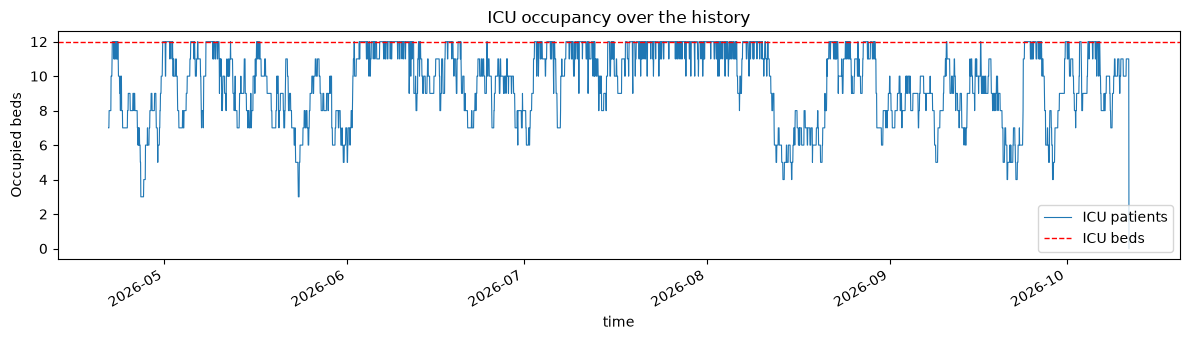

Average ICU occupancy by hour of day: [9.7, 9.7, 9.8, 9.8, 9.9, 9.8, 9.6, 9.6, 9.6, 9.5, 9.5, 9.5, 9.4, 9.4, 9.5, 9.6, 9.6, 9.6, 9.6, 9.6, 9.6, 9.6, 9.6, 9.8]
Average ICU occupancy by day (Mon..Sun): [9.0, 9.4, 9.7, 9.8, 10.0, 10.1, 9.3]


In [2]:
fig, ax = plt.subplots(figsize=(12, 3.5))
data["ICU"].plot(ax=ax, lw=0.8, label="ICU patients")
ax.axhline(ICU_BEDS, color="red", ls="--", lw=1, label="ICU beds")
ax.set_ylabel("Occupied beds")
ax.set_title("ICU occupancy over the history")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(RESULTS / "icu_history.png", dpi=150)
plt.show()

by_hour = data["ICU"].groupby(data.index.hour).mean()
by_day = data["ICU"].groupby(data.index.dayofweek).mean()
print("Average ICU occupancy by hour of day:", by_hour.round(1).tolist())
print("Average ICU occupancy by day (Mon..Sun):", by_day.round(1).tolist())

## Features: what the model looks at

Everything is known **at the moment of the forecast**; nothing from the future leaks in.

In [3]:
HORIZONS = [6, 12, 24, 48, 72]
LAGS = [0, 1, 2, 3, 6, 12, 24, 48, 168]


def make_features(frame):
    icu = frame["ICU"]
    features = pd.DataFrame(index=frame.index)
    for lag in LAGS:
        features[f"icu_{lag}h_ago"] = icu.shift(lag)
    features["icu_mean_24h"] = icu.rolling(24).mean()
    features["icu_admissions_24h"] = frame["icu_admissions"].rolling(24).sum()
    features["ed_arrivals_6h"] = frame["ed_arrivals"].rolling(6).sum()
    features["ed_arrivals_24h"] = frame["ed_arrivals"].rolling(24).sum()
    features["ward"] = frame["WARD"]
    features["ed"] = frame["ED"]
    features["hour"] = frame.index.hour
    features["weekday"] = frame.index.dayofweek
    return features


features = make_features(data)
FEATURES = list(features.columns)
targets = {h: data["ICU"].shift(-h) for h in HORIZONS}  # the true occupancy h hours later

test_start = data.index[-1] - pd.Timedelta(days=30)
validation_start = test_start - pd.Timedelta(days=14)
print("Training up to", validation_start.strftime("%d %b"), "· validation until", test_start.strftime("%d %b"),
      "· testing on the last 30 days")
features.tail(3)

Training up to 28 Aug · validation until 11 Sep · testing on the last 30 days


,icu_0h_ago,icu_1h_ago,icu_2h_ago,icu_3h_ago,icu_6h_ago,icu_12h_ago,icu_24h_ago,icu_48h_ago,icu_168h_ago,icu_mean_24h,icu_admissions_24h,ed_arrivals_6h,ed_arrivals_24h,ward,ed,hour,weekday
time,,,,,,,,,,,,,,,,,
2026-10-11 11:30:00+05:30,11,11.0,11.0,11.0,11.0,10.0,11.0,10.0,10.0,10.500000,2.0,11.0,28.0,31,5,11,6
2026-10-11 12:30:00+05:30,11,11.0,11.0,11.0,11.0,10.0,11.0,10.0,10.0,10.500000,2.0,12.0,27.0,31,5,12,6
2026-10-11 13:30:00+05:30,0,11.0,11.0,11.0,11.0,10.0,11.0,10.0,11.0,10.041667,2.0,11.0,27.0,1,1,13,6


## Train, choose and test

For each horizon:
1. Train on the older months; score the model, Holt-Winters and a 50/50 blend of the two on the **validation** weeks.
2. Keep the method with the lowest validation error, and size the 80% band from its validation errors.
3. Retrain on everything before the test period, and score every method on the **test** month.

The model is kept deliberately simple (small trees, at least 80 hours behind every decision), because with
about five months of hourly data a more flexible model memorises noise (*overfitting*); see the notes at the end.

In [4]:
def gradient_boosting():
    return HistGradientBoostingRegressor(max_iter=150, learning_rate=0.05, max_leaf_nodes=8,
                                         min_samples_leaf=80, l2_regularization=1.0, random_state=0)


def weekly_pattern(until):
    """Holt-Winters fitted on ICU occupancy before `until`; returns a function giving its forecast for given times."""
    series = data.loc[data.index < until, "ICU"].astype(float)
    fitted = ExponentialSmoothing(series.values, seasonal="add", seasonal_periods=168).fit()
    last_hour = series.index[-1]
    projection = fitted.forecast(24 * 50)
    return lambda times: projection[((times - last_hour) / pd.Timedelta(hours=1)).astype(int) - 1]


def split(h, train_until, evaluate_from, evaluate_until=None):
    y = targets[h]
    usable = features.notna().all(axis=1) & y.notna()
    train = usable & (features.index + pd.Timedelta(hours=h) < train_until)  # the answer must be known by then
    evaluate = usable & (features.index >= evaluate_from)
    if evaluate_until is not None:
        evaluate &= features.index + pd.Timedelta(hours=h) < evaluate_until
    return features[train], y[train], features[evaluate], y[evaluate]


pattern_for_validation = weekly_pattern(validation_start)
pattern_for_test = weekly_pattern(test_start)

rows, saved = [], {}
for h in HORIZONS:
    # 1-2: choose on the validation weeks
    X_train, y_train, X_val, y_val = split(h, validation_start, validation_start, test_start)
    model = gradient_boosting().fit(X_train, y_train)
    candidates = {
        "Gradient Boosting": model.predict(X_val),
        "Holt-Winters": pattern_for_validation(X_val.index + pd.Timedelta(hours=h)),
    }
    candidates["Blend (50/50)"] = (candidates["Gradient Boosting"] + candidates["Holt-Winters"]) / 2
    validation_mae = {name: mean_absolute_error(y_val, prediction) for name, prediction in candidates.items()}
    chosen = min(validation_mae, key=validation_mae.get)
    band = float(np.quantile(np.abs(y_val - candidates[chosen]), 0.8))  # 80% of validation errors are within this

    # 3: retrain on everything before the test, then test
    X_train, y_train, X_test, y_test = split(h, test_start, test_start)
    model = gradient_boosting().fit(X_train, y_train)
    target_times = X_test.index + pd.Timedelta(hours=h)
    predictions = {
        "Same as now": X_test["icu_0h_ago"].values,
        "Same time last week": data["ICU"].shift(168 - h)[X_test.index].values,
        "Holt-Winters": pattern_for_test(target_times),
        "Gradient Boosting": model.predict(X_test),
    }
    predictions["Blend (50/50)"] = (predictions["Gradient Boosting"] + predictions["Holt-Winters"]) / 2
    predictions["MedTwin forecast"] = predictions[chosen]
    for name, prediction in predictions.items():
        rows.append({"horizon_h": h, "method": name,
                     "MAE": mean_absolute_error(y_test, prediction),
                     "RMSE": root_mean_squared_error(y_test, prediction)})
    inside = (np.abs(y_test.values - predictions[chosen]) <= band).mean()
    rows.append({"horizon_h": h, "method": "Band coverage", "coverage": inside, "chosen": chosen, "band": band})
    saved[h] = {"method": chosen, "model": model, "band": band, "validation_mae": validation_mae}

results = pd.DataFrame(rows)
order = ["Same as now", "Same time last week", "Holt-Winters", "Gradient Boosting", "Blend (50/50)", "MedTwin forecast"]
table = results.dropna(subset=["MAE"]).pivot(index="method", columns="horizon_h", values="MAE").loc[order].round(2)
table.columns = [f"{h} h" for h in table.columns]
print("Test month, MAE (average error in beds), lower is better:")
table

D:\MedTwin\ml\.venv\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)


D:\MedTwin\ml\.venv\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)


Test month, MAE (average error in beds), lower is better:


,6 h,12 h,24 h,48 h,72 h
method,,,,,
Same as now,0.96,1.33,1.74,2.45,2.87
Same time last week,2.16,2.16,2.19,2.21,2.24
Holt-Winters,1.67,1.68,1.68,1.67,1.69
Gradient Boosting,0.97,1.23,1.66,1.83,1.96
Blend (50/50),1.18,1.38,1.63,1.71,1.79
MedTwin forecast,0.97,1.23,1.66,1.83,1.96


In [5]:
band_rows = results.dropna(subset=["coverage"]).set_index("horizon_h")
summary = pd.DataFrame({
    "method chosen on validation": band_rows["chosen"],
    "band (± beds)": band_rows["band"].round(1),
    "test values inside the band": (band_rows["coverage"] * 100).round(0).astype(int).astype(str) + "%",
})
print("The MedTwin forecast for each horizon (band should hold about 80% of real values):")
print(summary.to_string())

simple = table.loc[["Same as now", "Same time last week"]].min()
vs_simple = ((simple - table.loc["MedTwin forecast"]) / simple * 100).round(0).astype(int)
print()
print("MedTwin forecast vs the best simple rule (positive = better):")
print(vs_simple.astype(str).add("%").to_string())

results.to_csv(RESULTS / "icu_forecast_metrics.csv", index=False)

The MedTwin forecast for each horizon (band should hold about 80% of real values):
          method chosen on validation  band (± beds) test values inside the band
horizon_h                                                                       
6                   Gradient Boosting            1.3                         74%
12                  Gradient Boosting            1.9                         78%
24                  Gradient Boosting            2.7                         79%
48                  Gradient Boosting            2.2                         66%
72                  Gradient Boosting            2.2                         59%

MedTwin forecast vs the best simple rule (positive = better):
6 h     -1%
12 h     8%
24 h     5%
48 h    17%
72 h    13%


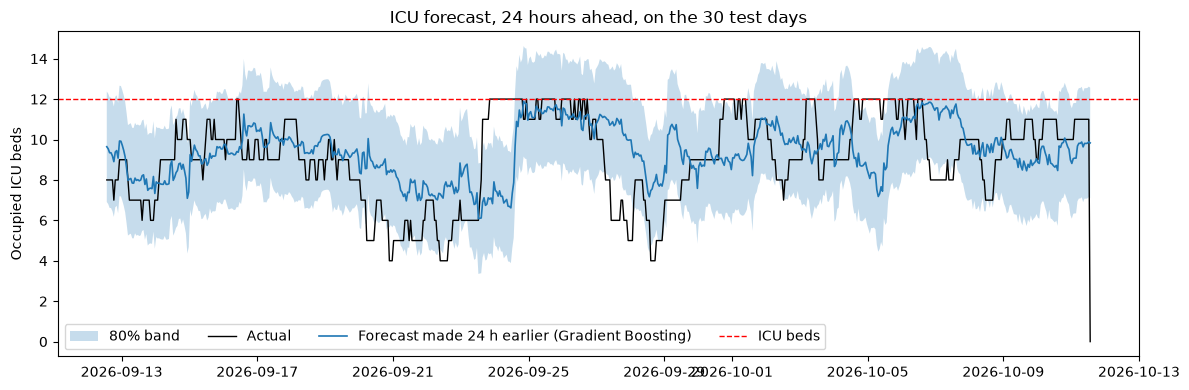

In [6]:
h = 24
X_train, y_train, X_test, y_test = split(h, test_start, test_start)
when = X_test.index + pd.Timedelta(hours=h)
options = {"Gradient Boosting": saved[h]["model"].predict(X_test), "Holt-Winters": pattern_for_test(when)}
options["Blend (50/50)"] = (options["Gradient Boosting"] + options["Holt-Winters"]) / 2
forecast = options[saved[h]["method"]]

fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(when, forecast - saved[h]["band"], forecast + saved[h]["band"], alpha=0.25, label="80% band")
ax.plot(when, y_test.values, color="black", lw=1, label="Actual")
ax.plot(when, forecast, lw=1.2, label=f"Forecast made 24 h earlier ({saved[h]['method']})")
ax.axhline(ICU_BEDS, color="red", ls="--", lw=1, label="ICU beds")
ax.set_ylabel("Occupied ICU beds")
ax.set_title("ICU forecast, 24 hours ahead, on the 30 test days")
ax.legend(loc="lower left", ncol=4)
plt.tight_layout()
plt.savefig(RESULTS / "icu_forecast_24h.png", dpi=150)
plt.show()

## What the 24-hour Gradient Boosting model relies on

**Permutation importance:** shuffle one feature at a time on the test data and see how much worse the
forecast gets. The bigger the drop, the more the model depends on that feature.

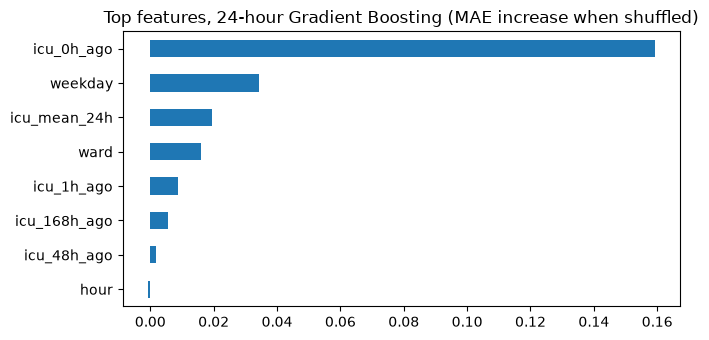

In [7]:
importance = permutation_importance(saved[24]["model"], X_test, y_test, n_repeats=5, random_state=0,
                                    scoring="neg_mean_absolute_error")
ranked = pd.Series(importance.importances_mean, index=FEATURES).sort_values(ascending=True).tail(8)
ax = ranked.plot.barh(figsize=(7, 3.5), title="Top features, 24-hour Gradient Boosting (MAE increase when shuffled)")
plt.tight_layout()
plt.savefig(RESULTS / "icu_forecast_importance.png", dpi=150)
plt.show()

## Save the models for the backend (Day 29)

The backend will load this file once and, every hospital hour, forecast the next 72 hours. For horizons that
use Holt-Winters, the backend refits it on recent weeks each time (it's quick), so the pattern stays current.

In [8]:
bundle = {
    "horizons": saved,
    "holt_winters": {"seasonal_periods": 168, "seasonal": "add"},
    "features": FEATURES,
    "lags": LAGS,
    "icu_beds": ICU_BEDS,
    "trained_until": str(test_start),
    "timezone": "Asia/Kolkata",
    "metrics": results.to_dict(orient="records"),
}
MODELS.mkdir(exist_ok=True)
joblib.dump(bundle, MODELS / "icu_forecast.joblib", compress=3)
print("Saved", MODELS / "icu_forecast.joblib", f"({(MODELS / 'icu_forecast.joblib').stat().st_size / 1e6:.1f} MB)")

Saved ..\models\icu_forecast.joblib (0.2 MB)


## Notes for the report

- **Short horizons (6–12 h):** the current situation matters most. ICU occupancy changes slowly, so "same as now"
  is already strong.
- **Long horizons (48–72 h):** nobody can know which patients will arrive, so every method meets a floor of
  roughly 1.7 beds; the **weekly pattern** (Holt-Winters) or a blend is the best available.
- **Choosing per horizon on a separate validation period**, and testing on an untouched month, keeps the comparison fair.
- **Overfitting:** an earlier, more flexible model (31-leaf trees, 300 rounds) was worse on the test month than
  this simpler one; with about five months of hourly data, simpler generalises better.
- **Prophet** was planned as the statistical baseline, but its Stan backend fails on this Windows setup; Holt-Winters
  seasonal exponential smoothing (statsmodels) plays the same role.